# C3 Vision Oracle: measured results for PP1

Every table and figure here is read from a file produced by an actual run on 20–21 October 2026, on the RTX 3050 4 GB laptop. Nothing is typed in by hand. Earlier PP1 notebooks (`00_`–`06_`) and the master evaluation notebook show figures that could not be reproduced with the shipped model. **Do not present them.**

| Section | Shows |
|---|---|
| 1 | What model and adapter are running |
| 2 | Training curves |
| 3 | Why the first deployment "detected nothing" |
| 4 | Held-out test results (the only accuracy numbers to quote) |
| 5 | Demo screens through the real app pipeline |
| 6 | Speed and memory |
| 7 | Global view vs tiles (validation) |
| 8 | Optional live run (needs the GPU) |

In [1]:
import json, math, hashlib
from pathlib import Path
import matplotlib.pyplot as plt
from PIL import Image
C3 = next(p for p in [Path.cwd().resolve(), *Path.cwd().resolve().parents] if (p / 'evidence' / '11_model_v2').exists())
EV = C3 / 'evidence'
ADAPTER = C3 / 'models' / 'c3_qwen2vl_2b_lora_step246'
load = lambda p: json.loads(Path(p).read_text(encoding='utf-8'))
print('vision_oracle folder:', C3)

vision_oracle folder: D:\university\Resesarch\J26-SE-334\vision_oracle


## 1. Identity: what is running

In [2]:
from safetensors import safe_open
cfg = load(ADAPTER / 'adapter_config.json')
contract = load(ADAPTER / 'inference_contract.json')
with safe_open(str(ADAPTER / 'adapter_model.safetensors'), 'pt') as f:
    trainable = sum(math.prod(f.get_slice(k).get_shape()) for k in f.keys())
    n_tensors = len(list(f.keys()))
sha = hashlib.sha256((ADAPTER / 'adapter_model.safetensors').read_bytes()).hexdigest()
TOTAL = 2_227_450_368  # base + adapter parameters, from the LLaMA-Factory training log
print(f"Base model        : Qwen2-VL-2B-Instruct (4-bit NF4, frozen)")
print(f"LoRA rank / alpha : {cfg['r']} / {cfg['lora_alpha']}, dropout {cfg['lora_dropout']}")
print(f"Adapted layers    : {sorted(cfg['target_modules'])} ({n_tensors} tensors)")
print(f"Trainable params  : {trainable:,} of {TOTAL:,} ({trainable/TOTAL:.2%})")
print(f"Adapter SHA-256   : {sha}")
print(f"Inference contract: {contract['image_max_pixels']:,} px, threshold {contract['decision_threshold']} ({contract['threshold_source']})")

Base model        : Qwen2-VL-2B-Instruct (4-bit NF4, frozen)
LoRA rank / alpha : 16 / 32, dropout 0.0
Adapted layers    : ['down_proj', 'gate_proj', 'k_proj', 'o_proj', 'q_proj', 'up_proj', 'v_proj'] (392 tensors)
Trainable params  : 18,464,768 of 2,227,450,368 (0.83%)
Adapter SHA-256   : 1a3642f57db0d85e1426216d1bbc32829a466f684cd85d82a83ad7ed711b6354
Inference contract: 262,144 px, threshold 0.5351 (F1-optimal on c3v2_val (291 screens), v1_step246; never tuned on test)


**Conclude:** fine-tuning changed 0.83% of the parameters. The prompt, resolution and decision threshold the model was trained and validated with travel with the weights.

## 2. Training curves

stage 1 steps 368 | stage 2 steps 246 | best validation checkpoint recorded: None


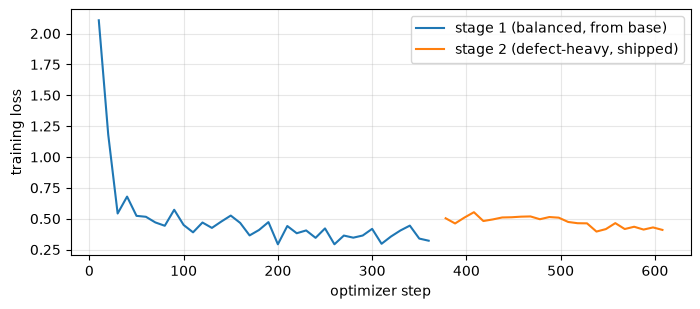

In [3]:
s1 = load('D:/university/Resesarch/results/c3_lora_clean_zero_leakage/trainer_state.json')
s2 = load(ADAPTER / 'trainer_state.json')
fig, ax = plt.subplots(figsize=(8, 3.2))
for st, name, off in ((s1, 'stage 1 (balanced, from base)', 0), (s2, 'stage 2 (defect-heavy, shipped)', s1['global_step'])):
    pts = [(h['step'] + off, h['loss']) for h in st['log_history'] if 'loss' in h]
    ax.plot(*zip(*pts), label=name)
ax.set_xlabel('optimizer step'); ax.set_ylabel('training loss'); ax.legend(); ax.grid(alpha=.3)
print('stage 1 steps', s1['global_step'], '| stage 2 steps', s2['global_step'], '| best validation checkpoint recorded:', s2.get('best_model_checkpoint'))

**Look at:** the loss falls fast, then flattens around 0.3–0.5. **Conclude:** training loss measures how well answer text is reproduced, not detection accuracy. No validation was run during this training, which is why section 4 matters.

## 3. Diagnosis: the same adapter, the same screens, two ways of asking

In [4]:
def caught(recs):
    tp = sum(r['gold_has'] and r['pred_has'] is True for r in recs)
    fn = sum(r['gold_has'] and r['pred_has'] is not True for r in recs)
    fp = sum((not r['gold_has']) and r['pred_has'] is True for r in recs)
    return f'{tp}/{tp+fn} defects caught, {fp} false alarms'
app = load(EV / '11_model_v2/diagnosis/v1_adapter_app_input_val18.json')
trn = load(EV / '11_model_v2/diagnosis/v1_adapter_training_input_val60.json')[:len(app)]
print('Old app input (40-line prompt, 720x1280):', caught(app))
print('Training input (short prompt, 262k px)  :', caught(trn))

Old app input (40-line prompt, 720x1280): 1/11 defects caught, 1 false alarms
Training input (short prompt, 262k px)  : 9/11 defects caught, 5 false alarms


**Conclude:** the weights had learned; the app asked differently from training. Each adapter now carries `inference_contract.json`, which the backend enforces.

## 4. Held-out test (316 screens, run once, never used for choices)

In [5]:
import sys; sys.path.insert(0, str(C3))
from local_vision_oracle.contract_benchmark import metrics_at
B = EV / '11_model_v2/benchmarks'
rows = []
for name, label in (('base_v2prompt', 'Base Qwen2-VL-2B, same prompt'), ('v1_step246', 'Shipped adapter (step 246)'),
                    ('v2_checkpoint-173', 'v2 retrain, epoch 1'), ('v2_epoch2', 'v2 retrain, epoch 2')):
    t = load(B / f'{name}_test316_scores.json'); thr = load(B / f'{name}_val291_scores.json')['best_threshold']['threshold']
    m = metrics_at([r['p_defect'] for r in t['records']], [r['gold_has'] for r in t['records']], thr)
    rows.append((label, t['auc'], t['auc_95ci'], thr, m['precision'], m['recall'], m['f1'], m['accuracy']))
print(f"{'model':32} {'AUC':>5} {'95% CI':>13} {'thr':>5} {'prec':>5} {'rec':>5} {'F1':>5} {'acc':>5}")
for r in rows:
    print(f"{r[0]:32} {r[1]:5.2f} {r[2][0]:5.2f}-{r[2][1]:4.2f} {r[3]:5.2f} {r[4]:5.0%} {r[5]:5.0%} {r[6]:5.2f} {r[7]:5.0%}")
mc = load(B / 'mcnemar_test316.json')
print('\nMcNemar, shipped vs base   :', mc['mcnemar_v1_vs_base'])
print('McNemar, shipped vs v2 ep2 :', mc['mcnemar_v1_vs_v2_epoch2'])

model                              AUC        95% CI   thr  prec   rec    F1   acc
Base Qwen2-VL-2B, same prompt     0.57  0.51-0.64  0.18   51%  100%  0.67   51%
Shipped adapter (step 246)        0.75  0.69-0.80  0.54   61%   79%  0.69   65%
v2 retrain, epoch 1               0.68  0.62-0.73  0.23   54%   91%  0.68   57%
v2 retrain, epoch 2               0.71  0.66-0.77  0.18   54%   94%  0.69   58%

McNemar, shipped vs base   : {'v1_only_correct': 76, 'base_only_correct': 34, 'chi2_cc': 15.2818, 'p': 9e-05}
McNemar, shipped vs v2 ep2 : {'v1_only_correct': 55, 'v2_only_correct': 33, 'chi2_cc': 5.0114, 'p': 0.02518}


**Look at:** AUC (0.5 = guessing) and accuracy. The base model reaches F1 0.67 only by flagging every screen. **Conclude:** fine-tuning added real detection skill (p = 0.0001). The 70% F1 target is narrowly missed. Thresholds were chosen on validation (291 screens), never on test.

End to end through the production backend (decision + type + box):
{'precision': 0.6139, 'recall': 0.7848, 'f1': 0.6889, 'accuracy': 0.6456, 'invalid_outputs': 0, 'type_accuracy_on_defects': 0.3544, 'iou_at_0_5_on_defects': 0.0823}


Text(0.5, 1.0, 'Defect vs clean, by true class (test)')

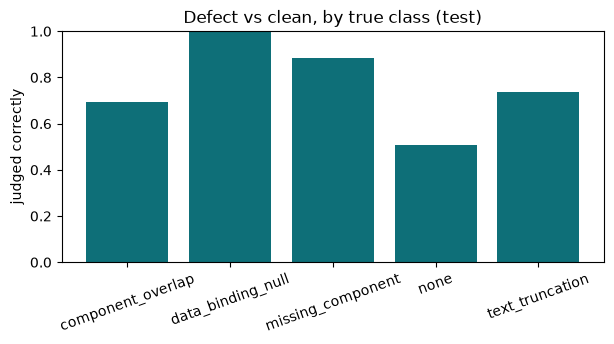

In [6]:
e2e = load(B / 'final_test316_end_to_end.json')
s = e2e['summary']
print('End to end through the production backend (decision + type + box):')
print({k: s[k] for k in ('precision', 'recall', 'f1', 'accuracy', 'invalid_outputs', 'type_accuracy_on_defects', 'iou_at_0_5_on_defects')})
import numpy as np
names = sorted(s['per_class'])
fig, ax = plt.subplots(figsize=(7, 3))
ax.bar(names, [s['per_class'][k]['binary_correct'] / s['per_class'][k]['n'] for k in names], color='#0e6f78')
ax.set_ylim(0, 1); ax.set_ylabel('judged correctly'); plt.xticks(rotation=20); ax.set_title('Defect vs clean, by true class (test)')

**Conclude:** 'none' at about 50% means half the clean screens raise a false alarm, the main weakness. Defect type is right on 35% and boxes overlap well (IoU ≥ 0.5) on 8%: localization is the weakest skill, limited by noisy type and box labels.

## 5. Demo screens through the real app pipeline
Selected held-out test screens, re-run through the same code as the HEART desktop app. Green = expected region, red = model region. These show behaviour; they are not the accuracy.

#1 bug.4031.jpg             expected component_overlap  app: defect_detected     component_overlap  score 0.8245
#2 bug.4007.jpg             expected component_overlap  app: defect_detected     component_overlap  score 0.6689
#3 bug.4418.jpg             expected data_binding_null  app: defect_detected     data_binding_null  score 0.9252
#4 bug.4037.jpg             expected missing_component  app: defect_detected     missing_component  score 0.8933
#5 11083_mut_missing.jpg    expected missing_component  app: defect_detected     missing_component  score 0.9185
#6 13067_mut_overlap.jpg    expected component_overlap  app: defect_detected     component_overlap  score 0.6406
#7 normal.4234.jpg          expected none               app: no_defect_detected  none               score 0.363
#8 14229.jpg                expected none               app: no_defect_detected  none               score 0.3558
#9 bug.4296.jpg             expected text_truncation    app: no_defect_detected  none            

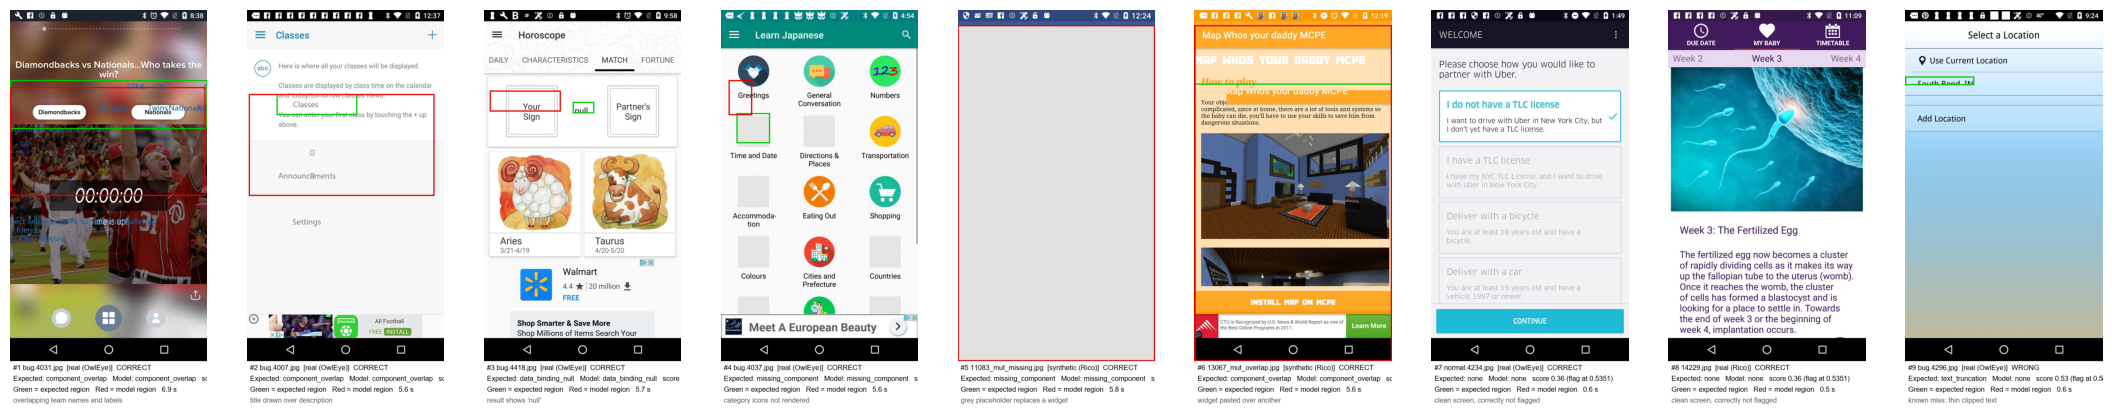

In [7]:
demo = load(EV / '13_pp1_demo/demo_results.json')
for r in demo:
    print(f"#{r['n']} {Path(r['image']).name:24} expected {r['expected_type']:18} app: {r['decision']:19} {r['predicted_type']:18} score {r['defect_score']}")
imgs = sorted((EV / '13_pp1_demo').glob('*.png'))
fig, axes = plt.subplots(1, len(imgs), figsize=(3 * len(imgs), 7))
for ax, p in zip(axes, imgs):
    ax.imshow(Image.open(p)); ax.axis('off')

## 6. Speed and memory (measured, model loaded once)

In [8]:
score = load(B / 'v1_step246_test316_scores.json')['records']
lat_decision = sorted(r['latency_ms'] for r in score)
lat_e2e = sorted(r['latency_ms'] for r in e2e['records'])
flagged = sorted(r['latency_ms'] for r in e2e['records'] if r['pred_has'])
q = lambda v, p: v[min(len(v) - 1, int(len(v) * p))] / 1000
print(f"Decision only (one forward pass): median {q(lat_decision,.5):.2f} s, p95 {q(lat_decision,.95):.2f} s")
print(f"Flagged screens, incl. type+box : median {q(flagged,.5):.1f} s, p95 {q(flagged,.95):.1f} s")
print(f"All screens end to end          : median {q(lat_e2e,.5):.1f} s")
print(f"Peak GPU memory (PyTorch)       : {e2e['peak_vram_bytes']/2**30:.2f} GB of 4 GB")
off = load(EV / '14_pipeline_audit/offline_inference_check.json')
print(f"Offline run (all sockets blocked): {off['decision']}, network attempts = {len(off['network_connection_attempts'])}")

Decision only (one forward pass): median 0.63 s, p95 0.67 s
Flagged screens, incl. type+box : median 8.6 s, p95 27.6 s
All screens end to end          : median 8.0 s
Peak GPU memory (PyTorch)       : 1.71 GB of 4 GB
Offline run (all sockets blocked): defect_detected, network attempts = 0


**Conclude:** the defect/clean decision meets the 1.5 s target; generating the type and box does not. Offline was tested, not assumed: with every network connection blocked, inference still completes and makes zero connection attempts.

## 7. Global view vs tiled views (validation only)

In [9]:
p = EV / '14_pipeline_audit/tile_ablation_val60.json'
if p.exists():
    t = load(p)
    for pol, v in t['policies'].items():
        m = v['summary']
        print(f"{pol:22} prec {m['precision']:.0%} rec {m['recall']:.0%} F1 {m['f1']:.2f} acc {m['accuracy']:.0%} false alarms {m['fp']} median {m['median_latency_ms']/1000:.1f} s")
else:
    print('Tile ablation not run yet:', p)

global_only            prec 59% rec 79% F1 0.68 acc 65% false alarms 15 median 5.5 s
global_plus_tiles_v1   prec 49% rec 100% F1 0.66 acc 52% false alarms 29 median 20.9 s


**Conclude:** this decides whether tile views stay off in the app.

## 8. Optional live run (GPU, about 40 s including model load)
Set `RUN_LIVE = True` to analyse one demo screen with the real model through the app's pipeline.

In [10]:
RUN_LIVE = False
if RUN_LIVE:
    sys.path.insert(0, str(C3.parent))
    import vision_oracle.services.oracle_service as svc
    from vision_oracle.local_vision_oracle.pipeline import AnalysisPipeline
    pipe = AnalysisPipeline(backend=svc.create_default_engine().backend, model_run_id='pp1-live')
    v = pipe.analyze(image=Image.open('C:/Games/OwlEye/Dataset/bug-aug/bug-aug/bug.4418.jpg').convert('RGB'), coverage_policy='global_only')
    print(v.decision, [(f.type, f.bbox_xyxy) for f in v.findings], v.metadata.get('defect_probability'), v.timings_ms)